# Домашнє завдання, заняття 4)

Ім’я: Фомічова Катерина   Дата: 16.11.2026

Тема: Alzheimer’s Disease Dataset / Набір даних про хворобу Альцгеймера

## Запитання й аудиторія
Запитання: Які характеристики пацієнтів пов'язані з наявністю діагнозу хвороби Альцгеймера?

Аудиторія: дослідник даних (Data Analyst), який аналізує характеристики пацієнтів і шукає можливі статистичні закономірності, пов'язані з діагнозом хвороби Альцгеймера.

## Дані
Запустіть клітинку або завантажте власний датасет.

In [38]:
import pandas as pd
import numpy as np

df = pd.read_csv("../Lesson3/alzheimers_disease_data.csv")
print(df.head())
print(df.columns.tolist())

   PatientID  Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
0       4751   73       0          0               2  22.927749        0   
1       4752   89       0          0               0  26.827681        0   
2       4753   73       0          3               1  17.795882        0   
3       4754   74       1          0               1  33.800817        1   
4       4755   89       0          0               0  20.716974        0   

   AlcoholConsumption  PhysicalActivity  DietQuality  ...  MemoryComplaints  \
0           13.297218          6.327112     1.347214  ...                 0   
1            4.542524          7.619885     0.518767  ...                 0   
2           19.555085          7.844988     1.826335  ...                 0   
3           12.209266          8.428001     7.435604  ...                 0   
4           18.454356          6.310461     0.795498  ...                 0   

   BehavioralProblems       ADL  Confusion  Disorientation  \
0     

## Зведена таблиця (groupby / pivot_table)

Середній вік пацієнтів залежно від статі та статусу куріння.

In [39]:
df.groupby(["Gender", "Smoking"])["Age"].mean().round(0)

Gender  Smoking
0       0          75.0
        1          75.0
1       0          75.0
        1          75.0
Name: Age, dtype: float64

Середній вік пацієнтів залежно від рівня фізичної активності.

In [40]:
df.groupby("Age")["PhysicalActivity"].mean().round(2)

Age
60    4.98
61    4.56
62    5.17
63    5.22
64    4.72
65    4.92
66    5.03
67    4.77
68    5.22
69    4.53
70    4.63
71    4.70
72    5.50
73    5.42
74    4.64
75    5.56
76    5.27
77    5.16
78    4.34
79    4.59
80    5.43
81    3.98
82    5.06
83    4.48
84    4.33
85    4.60
86    5.16
87    5.33
88    4.61
89    5.24
90    5.01
Name: PhysicalActivity, dtype: float64

Cередній рівень загального холестерину у пацієнтів із діабетом та без нього

In [41]:
df.groupby("Diabetes")["CholesterolTotal"].mean().round(2)

Diabetes
0    224.32
1    230.12
Name: CholesterolTotal, dtype: float64

Кількість пацієнтів із діагнозом та без нього залежно від статі

In [42]:
gender_diagnosis_count=df.pivot_table(index="Gender", columns="Diagnosis", values="PatientID", aggfunc="count")
print(gender_diagnosis_count)

Diagnosis    0    1
Gender             
0          675  386
1          714  374


Середній індекс маси тіла (BMI) залежно від статі та статусу куріння

In [43]:
BMI_mean=df.pivot_table(index="Gender", columns="Smoking", values="BMI", aggfunc="mean").round(2)
print(BMI_mean)

Smoking      0      1
Gender               
0        27.58  27.69
1        27.54  28.07


Середній рівень загального холестерину залежно від наявності діабету та статі

In [44]:
Cholesterol_mean=df.pivot_table(index="Gender", columns="Diabetes", values="CholesterolTotal", aggfunc="mean").round(2)
print(Cholesterol_mean)

Diabetes       0       1
Gender                  
0         225.32  227.16
1         223.37  233.27


## Об’єднання таблиць і перевірка (assert)

In [45]:
patient_info=df[["PatientID", "Gender", "Age", "Ethnicity", "EducationLevel"]]
print(patient_info)

      PatientID  Gender  Age  Ethnicity  EducationLevel
0          4751       0   73          0               2
1          4752       0   89          0               0
2          4753       0   73          3               1
3          4754       1   74          0               1
4          4755       0   89          0               0
...         ...     ...  ...        ...             ...
2144       6895       0   61          0               1
2145       6896       0   75          0               2
2146       6897       0   77          0               1
2147       6898       1   78          3               1
2148       6899       0   72          0               2

[2149 rows x 5 columns]


In [46]:
medical_data=df[["PatientID", "Diagnosis", "BMI", "CholesterolTotal", "PhysicalActivity"]]
print(medical_data)

      PatientID  Diagnosis        BMI  CholesterolTotal  PhysicalActivity
0          4751          0  22.927749        242.366840          6.327112
1          4752          0  26.827681        231.162595          7.619885
2          4753          0  17.795882        284.181858          7.844988
3          4754          0  33.800817        159.582240          8.428001
4          4755          0  20.716974        237.602184          6.310461
...         ...        ...        ...               ...               ...
2144       6895          1  39.121757        280.476824          4.049964
2145       6896          1  17.857903        186.384436          1.360667
2146       6897          1  15.476479        237.024558          9.886002
2147       6898          1  15.299911        242.197192          6.354282
2148       6899          0  33.289738        283.396797          6.570993

[2149 rows x 5 columns]


In [47]:
merged_data=patient_info.merge(medical_data, on="PatientID", how="left")
print(merged_data.head())

   PatientID  Gender  Age  Ethnicity  EducationLevel  Diagnosis        BMI  \
0       4751       0   73          0               2          0  22.927749   
1       4752       0   89          0               0          0  26.827681   
2       4753       0   73          3               1          0  17.795882   
3       4754       1   74          0               1          0  33.800817   
4       4755       0   89          0               0          0  20.716974   

   CholesterolTotal  PhysicalActivity  
0        242.366840          6.327112  
1        231.162595          7.619885  
2        284.181858          7.844988  
3        159.582240          8.428001  
4        237.602184          6.310461  


In [48]:
assert len(df)==len(merged_data)

## Розподіл (describe + гістограма або boxplot)

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
print(df["Age"].describe().round(1))

count    2149.0
mean       74.9
std         9.0
min        60.0
25%        67.0
50%        75.0
75%        83.0
max        90.0
Name: Age, dtype: float64


In [51]:
df_gender_0 = df[df["Gender"] == 0]
print(df_gender_0.shape)

(1061, 35)


In [52]:
df_gender_1 = df[df["Gender"] == 1]
print(df_gender_1.shape)

(1088, 35)


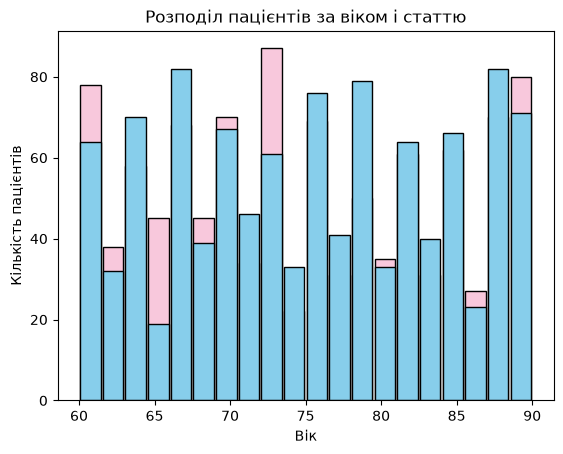

In [53]:
plt.hist(df_gender_0["Age"], bins=20, color="#F8C8DC", edgecolor="black", label="Gender 0", rwidth=0.9)

plt.hist(df_gender_1["Age"], bins=20, color="skyblue", edgecolor="black", label="Gender 1", rwidth=0.9)

plt.title("Розподіл пацієнтів за віком і статтю")
plt.xlabel("Вік")
plt.ylabel("Кількість пацієнтів")
plt.show()

In [54]:
df["CholesterolTotal"].describe().round(2)

count    2149.00
mean      225.20
std        42.54
min       150.09
25%       190.25
50%       225.09
75%       262.03
max       299.99
Name: CholesterolTotal, dtype: float64

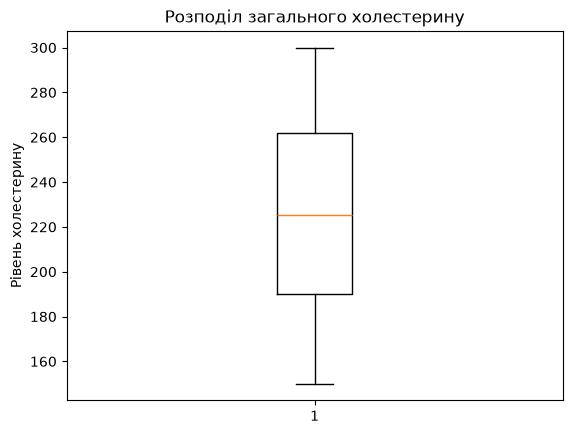

In [55]:
plt.boxplot(df["CholesterolTotal"])
plt.title("Розподіл загального холестерину")
plt.ylabel("Рівень холестерину")
plt.show()

## Візуальна історія: 5–7 діаграм

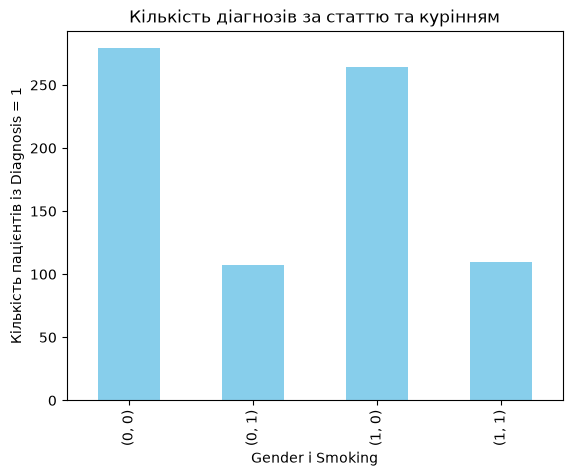

In [56]:
diagnosis_by_gender_smoking=df.groupby(["Gender","Smoking"])["Diagnosis"].sum()

diagnosis_by_gender_smoking.plot(kind="bar", color="skyblue")

plt.title("Кількість діагнозів за статтю та курінням")
plt.xlabel("Gender і Smoking")
plt.ylabel("Кількість пацієнтів із Diagnosis = 1")
plt.show()

Висновок: Кількість пацієнтів із діагнозом хвороби Альцгеймера відрізняється залежно від поєднання статі та статусу куріння.

Обмеження: Діаграма показує абсолютну кількість діагнозів, а не відсоток у кожній групі. Тому не можна зробити висновок про вплив куріння або статі на ризик захворювання.

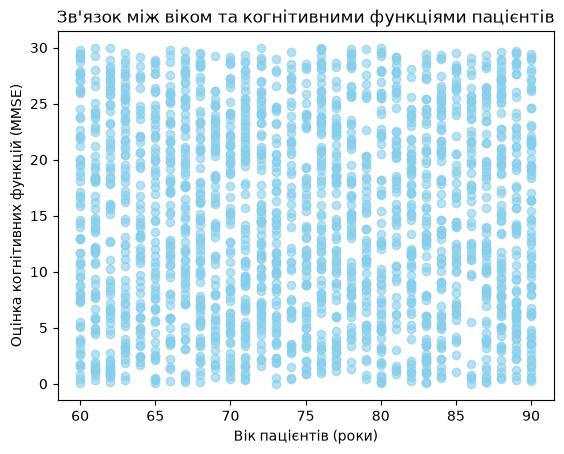

In [57]:
plt.scatter(df["Age"], df["MMSE"], color="skyblue", alpha=0.6)

plt.title("Зв'язок між віком та когнітивними функціями пацієнтів")
plt.xlabel("Вік пацієнтів (роки)")
plt.ylabel("Оцінка когнітивних функцій (MMSE)")
plt.show()


Висновок: Діаграма показує розподіл оцінок когнітивних функцій у пацієнтів різного віку, без чіткого лінійного зв'язку між цими показниками.

Обмеження: Діаграма не доводить причинно-наслідкового зв'язку між віком та когнітивними функціями.

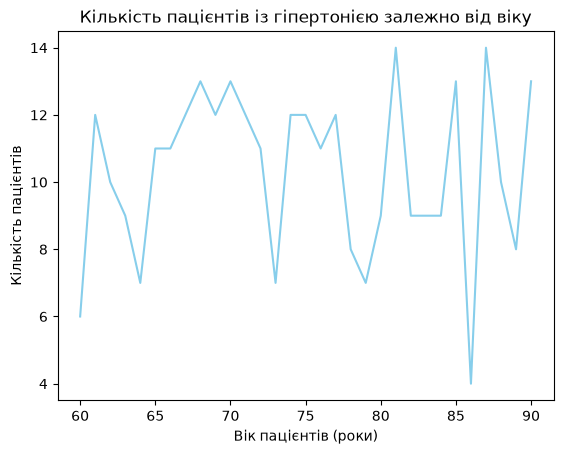

In [58]:
hypertension_by_age = df.groupby("Age")["Hypertension"].sum()

hypertension_by_age.plot(kind="line", color="skyblue")

plt.title("Кількість пацієнтів із гіпертонією залежно від віку")
plt.xlabel("Вік пацієнтів (роки)")
plt.ylabel("Кількість пацієнтів")
plt.show()


Висновок: Кількість пацієнтів із гіпертонією коливається від 4 до 14 осіб у різних вікових групах, без чіткої тенденції до зростання або зменшення з віком.

Обмеження: Діаграма показує кількість випадків, а не відсоток пацієнтів із гіпертонією в кожній віковій групі.

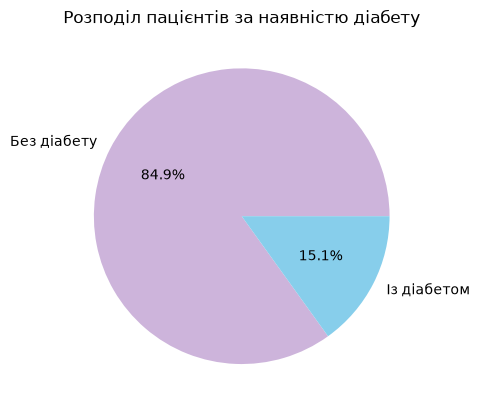

In [59]:
df["Diabetes"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    colors=["#CDB4DB", "skyblue"],
    labels=["Без діабету", "Із діабетом"]
)

plt.title("Розподіл пацієнтів за наявністю діабету")
plt.ylabel("")
plt.show()


Висновок: Більшість пацієнтів (84,9%) не мають діабету, тоді як у 15,1% пацієнтів він присутній.

Обмеження: Діаграма показує лише загальний розподіл діабету та не відображає його зв'язок із діагнозом хвороби Альцгеймера.

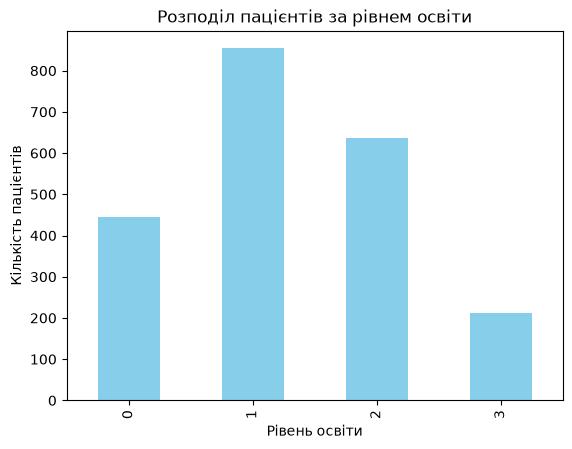

In [60]:
df["EducationLevel"].value_counts().sort_index().plot(
    kind="bar",
    color="skyblue"
)

plt.title("Розподіл пацієнтів за рівнем освіти")
plt.xlabel("Рівень освіти")
plt.ylabel("Кількість пацієнтів")
plt.show()


Висновок: Найбільша кількість пацієнтів належить до категорії рівня освіти 1 (854 особи), а найменша - до категорії 3 (213 осіб).

Обмеження: Числові категорії рівня освіти не розшифровані, тому неможливо визначити конкретний рівень освіти пацієнтів.

## Примітка про AI
Використовувала AI для вибору типів діаграм, пояснення команд Python та допомоги у формулюванні висновків і обмежень. Відхилила пропозиції повторно використовувати BMI та MMSE для інших графіків, обравши натомість гіпертонію та інші показники. Самостійно виконувала код, перевіряла результати групування, статистичні показники та відповідність діаграм даним.